# Superstore Sales Performance

Where is this business actually making money, and where is it just moving volume?

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
%matplotlib inline

df = pd.read_csv("../data/Sample-Superstore.csv", encoding="latin1")
df["Order Date"] = pd.to_datetime(df["Order Date"], format="%m/%d/%Y")
df.shape

(9994, 21)

In [2]:
print("date range:", df["Order Date"].min().date(), "-", df["Order Date"].max().date())
print("total sales: ${:,.0f}".format(df["Sales"].sum()))
print("total profit: ${:,.0f}".format(df["Profit"].sum()))
print("margin: {:.1f}%".format(100 * df["Profit"].sum() / df["Sales"].sum()))

date range: 2014-01-03 - 2017-12-30
total sales: $2,297,201
total profit: $286,397
margin: 12.5%


4 years of orders (2014-2017), $2.3M in sales, but only $286K profit — a 12.5% margin. That's thin enough that it's worth checking whether it's thin everywhere or dragged down by a few categories.

## Monthly sales trend

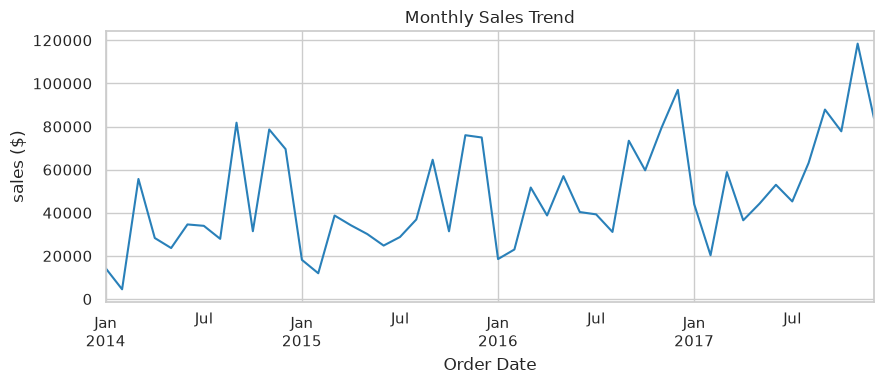

In [3]:
monthly = df.set_index("Order Date").resample("ME")["Sales"].sum()

monthly.plot(figsize=(9,4), color="#2980b9")
plt.ylabel("sales ($)")
plt.title("Monthly Sales Trend")
plt.tight_layout()
plt.show()

Clear seasonality — sales spike every November/December and dip in the first couple months of the year. Nothing surprising for retail, but it's a real pattern across all 4 years, not noise, so inventory and staffing should be planned around it rather than averaged out.

## Sales & profit by category

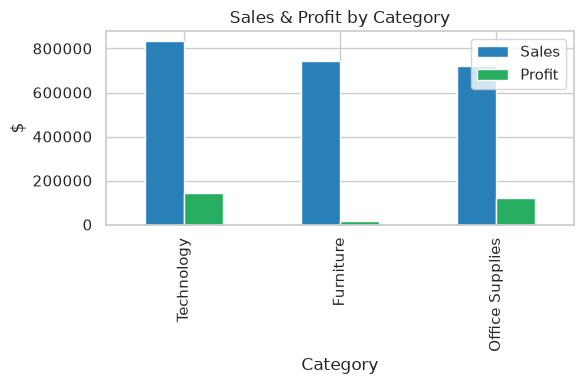

In [4]:
cat = df.groupby("Category")[["Sales", "Profit"]].sum().sort_values("Sales", ascending=False)
cat

cat.plot(kind="bar", figsize=(6,4), color=["#2980b9", "#27ae60"])
plt.ylabel("$")
plt.title("Sales & Profit by Category")
plt.tight_layout()
plt.show()

Furniture sells almost as much as Technology ($742K vs $836K) but makes a fraction of the profit ($18K vs $145K). That's not a demand problem, people are buying furniture just fine, it's a margin problem somewhere inside the category.

## Drilling into sub-categories

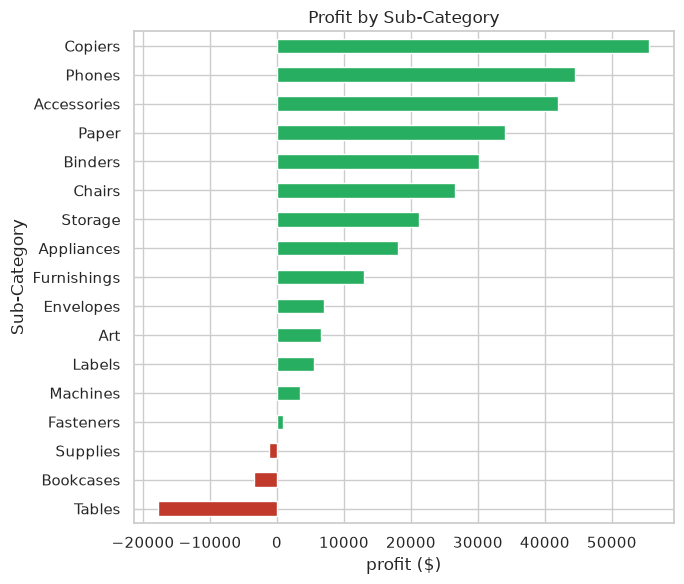

In [5]:
subcat = df.groupby("Sub-Category")["Profit"].sum().sort_values()
subcat.head(5)

plt.figure(figsize=(7,6))
subcat.plot(kind="barh", color=subcat.apply(lambda x: "#c0392b" if x < 0 else "#27ae60"))
plt.xlabel("profit ($)")
plt.title("Profit by Sub-Category")
plt.tight_layout()
plt.show()

Found it: **Tables lose $17.7K** and **Bookcases lose $3.5K**, both inside Furniture. Every other sub-category is at least breaking even. Two sub-categories are responsible for the entire margin problem in that category.

## Does discounting explain the losses?

In [6]:
df["discount_tier"] = pd.cut(df["Discount"], bins=[-0.01, 0, 0.2, 0.4, 1],
                              labels=["no discount", "1-20%", "21-40%", "40%+"])
df.groupby("discount_tier")["Profit"].agg(["count", "sum", "mean"])

,count,sum,mean
discount_tier,,,
no discount,4798,320987.6032,66.900292
1-20%,3803,100785.4745,26.501571
21-40%,460,-35817.4655,-77.864055
40%+,933,-99558.5905,-106.708028


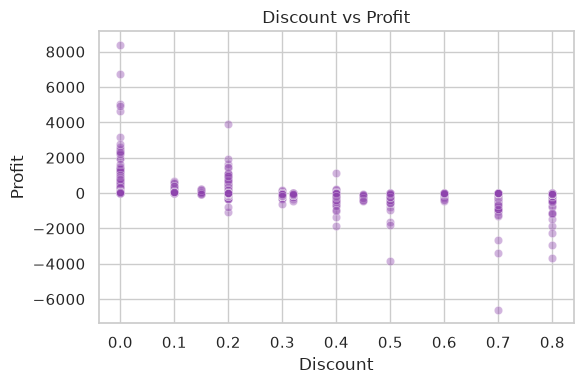

In [7]:
plt.figure(figsize=(6,4))
sns.scatterplot(data=df, x="Discount", y="Profit", alpha=0.4, color="#8e44ad")
plt.title("Discount vs Profit")
plt.tight_layout()
plt.show()

Yes. Orders with no discount average a healthy profit per order. Past 20% discount, average profit per order goes negative, and at 40%+ it's deeply negative. This lines up with the Tables/Bookcases problem — worth checking whether those sub-categories are the ones getting discounted hardest (likely, given how big the furniture discounts tend to run in this dataset).

## Regions

In [8]:
region = df.groupby("Region")[["Sales", "Profit"]].sum().sort_values("Sales", ascending=False)
region["margin_pct"] = (100 * region["Profit"] / region["Sales"]).round(1)
region

,Sales,Profit,margin_pct
Region,,,
West,725457.8245,108418.4489,14.9
East,678781.2400,91522.7800,13.5
Central,501239.8908,39706.3625,7.9
South,391721.9050,46749.4303,11.9


Central has decent sales ($501K) but the weakest margin of any region (7.9%, vs 13-15% elsewhere). Same shape as the Furniture problem — volume is fine, profitability isn't. Likely the same root cause: heavier discounting in that region, but that'd need a region x discount cross-check to confirm.

## Top products by sales

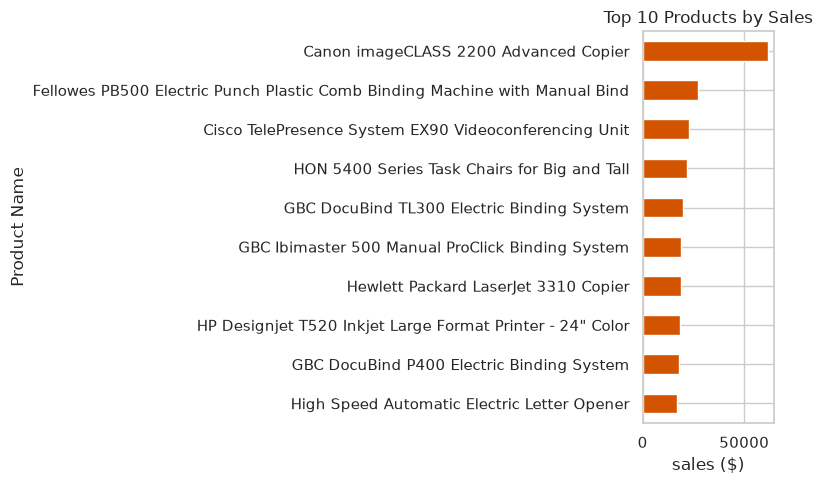

In [9]:
top_products = df.groupby("Product Name")["Sales"].sum().sort_values(ascending=False).head(10)

plt.figure(figsize=(8,5))
top_products.sort_values().plot(kind="barh", color="#d35400")
plt.xlabel("sales ($)")
plt.title("Top 10 Products by Sales")
plt.tight_layout()
plt.show()

Office equipment (copiers, binding machines, a videoconferencing unit) dominates the top 10 — these are big-ticket, low-frequency purchases, not everyday office supplies. Makes sense that a handful of expensive machines would outrank high-volume cheap items on total sales.

## Takeaways

- 12.5% overall margin, but it's not even — Furniture sells nearly as much as Technology ($742K vs $836K) yet profits a fraction as much ($18K vs $145K).
- Two sub-categories, Tables and Bookcases, are responsible for the whole Furniture margin problem — both are net-negative.
- Profit per order goes negative past a 20% discount, and craters past 40% — the discount policy is actively losing money on a meaningful share of orders.
- Central region has solid sales volume but the weakest margin (7.9%) of any region, worth a closer look at regional discounting practices.